# Producción de pintura Verde Manzana y Verde Pino

En este ejercicio se desea determinar cuántos litros de dos tipos de pintura debemos producir para **maximizar el beneficio** utilizando los recursos disponibles.

Los productos son:
- **Verde Manzana (x1)**: cada litro necesita 0.3 L de pintura azul y 0.7 L de pintura amarilla. Produce un beneficio de **1 € por litro**.
- **Verde Pino (x2)**: cada litro necesita 0.5 L de pintura azul y 0.5 L de pintura amarilla. Produce un beneficio de **1.20 € por litro**.

Recursos disponibles:
- 20 L de pintura azul.
- 28 L de pintura amarilla.

Además, no se pueden producir más de **30 L de Verde Manzana**.

## 1. Variables de decisión

Definimos:

- $x_1$ = litros de **Verde Manzana** que se producen.
- $x_2$ = litros de **Verde Pino** que se producen.

Como no podemos producir cantidades negativas:

$$x_1 \geq 0, \qquad x_2 \geq 0$$

## 2. Función objetivo

El beneficio por litro de Verde Manzana es 1 € y el de Verde Pino es 1.20 €.

Por tanto, queremos maximizar:

$$\max Z = 1x_1 + 1.20x_2$$

## 3. Restricciones

### Pintura azul

Cada litro de Verde Manzana consume 0.3 L de azul y cada litro de Verde Pino consume 0.5 L. Hay 20 L disponibles:

$$0.3x_1 + 0.5x_2 \leq 20$$

### Pintura amarilla

Cada litro de Verde Manzana consume 0.7 L de amarillo y cada litro de Verde Pino consume 0.5 L. Hay 28 L disponibles:

$$0.7x_1 + 0.5x_2 \leq 28$$

### Límite de Verde Manzana

No se pueden producir más de 30 L:

$$x_1 \leq 30$$

### No negatividad

$$x_1 \geq 0, \qquad x_2 \geq 0$$

## 4. Problema planteado

$$\begin{aligned}
\max\quad & Z = x_1 + 1.2x_2\\
\text{sujeto a}\quad & 0.3x_1 + 0.5x_2 \leq 20\\
& 0.7x_1 + 0.5x_2 \leq 28\\
& x_1 \leq 30\\
& x_1,x_2 \geq 0
\end{aligned}$$

## 5. Código

In [5]:
# Importar Pyomo
from pyomo.environ import *

# Crear el modelo
model = ConcreteModel()

# Definir las variables
model.x1 = Var(within=NonNegativeReals)  # Litros de Verde Manzana, no puede ser negativo
model.x2 = Var(within=NonNegativeReals)  # Litros de Verde Pino, no puede ser negativo

# Definir la función objetivo
model.obj = Objective(
    expr=1*model.x1 + 1.20*model.x2,
    sense=maximize
)

# Restricción de pintura azul
model.constraint1 = Constraint(
    expr=0.3*model.x1 + 0.5*model.x2 <= 20
)

# Restricción de pintura amarilla
model.constraint2 = Constraint(
    expr=0.7*model.x1 + 0.5*model.x2 <= 28
)

# Límite de producción de Verde Manzana
model.constraint3 = Constraint(
    expr=model.x1 <= 30
)

# Resolver el problema
solver = SolverFactory('glpk')
results = solver.solve(model, tee=False)

# Comprobar el estado de la solución
print('Estado:', results.solver.status)
print('Terminación:', results.solver.termination_condition)

# Mostrar los resultados
print(f'Verde Manzana (x1): {value(model.x1):.2f} L')
print(f'Verde Pino (x2): {value(model.x2):.2f} L')
print(f'Beneficio máximo: {value(model.obj):.2f} €')

x1 = value(model.x1)
x2 = value(model.x2)

azul_usado = 0.3*x1 + 0.5*x2
amarillo_usado = 0.7*x1 + 0.5*x2

print(f'Pintura azul utilizada: {azul_usado:.2f} L de 20 L')
print(f'Pintura azul sobrante: {20 - azul_usado:.2f} L')
print(f'Pintura amarilla utilizada: {amarillo_usado:.2f} L de 28 L')
print(f'Pintura amarilla sobrante: {28 - amarillo_usado:.2f} L')
print(f'Verde Manzana producida: {x1:.2f} L de un máximo de 30 L')
print(f'Verde Pino producido: {x2:.2f} L de un máximo de 30 L')

Estado: ok
Terminación: optimal
Verde Manzana (x1): 20.00 L
Verde Pino (x2): 28.00 L
Beneficio máximo: 53.60 €
Pintura azul utilizada: 20.00 L de 20 L
Pintura azul sobrante: 0.00 L
Pintura amarilla utilizada: 28.00 L de 28 L
Pintura amarilla sobrante: 0.00 L
Verde Manzana producida: 20.00 L de un máximo de 30 L
Verde Pino producido: 28.00 L de un máximo de 30 L


## 6. Interpretación de la solución

El modelo determina una producción de **20 L de Verde Manzana** y **28 L de Verde Pino**, con un **beneficio máximo de 53,60 €**.

La solución utiliza completamente los **20 L de pintura azul** disponibles. En cambio, se utilizan **28 L de pintura amarilla**, por lo que también se agota este recurso.

El límite de 30 L de Verde Manzana no es vinculante, ya que se producen 20 L.

Por tanto, la respuesta al ejercicio es:

| Concepto | Resultado |
|---|---:|
| Verde Manzana | **20 L** |
| Verde Pino | **28 L** |
| Beneficio máximo | **53,60 €** |
| Azul utilizado | **20 L** |
| Amarillo utilizado | **28 L** |

## 7. Resolución gráfica

Estado del solver: ok
Condición de terminación: optimal

RESULTADO ÓPTIMO
Verde Manzana: 20.00 L
Verde Pino: 28.00 L
Beneficio máximo: 53.60 €

RECURSOS UTILIZADOS
Pintura azul utilizada: 20.00 L de 20 L
Pintura azul sobrante: 0.00 L
Pintura amarilla utilizada: 28.00 L de 28 L
Pintura amarilla sobrante: 0.00 L


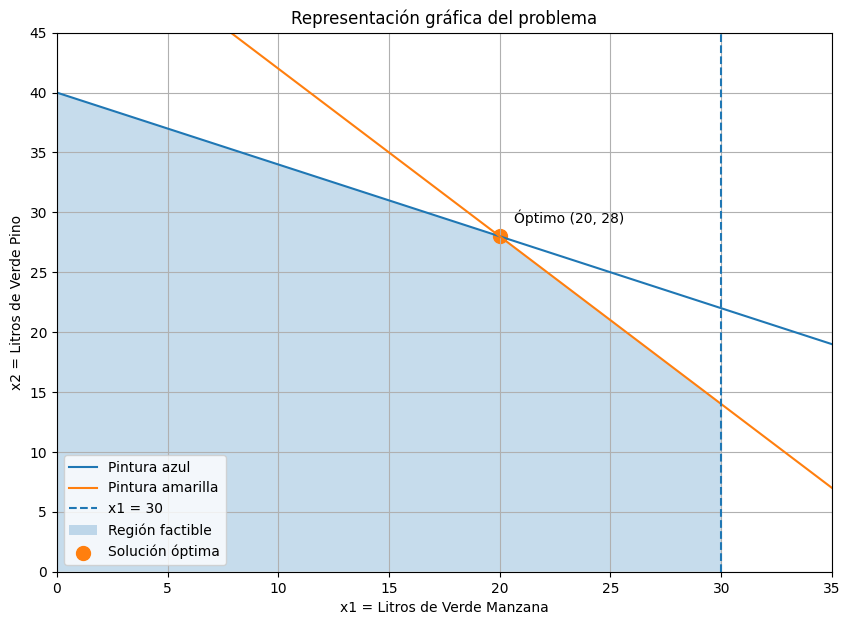

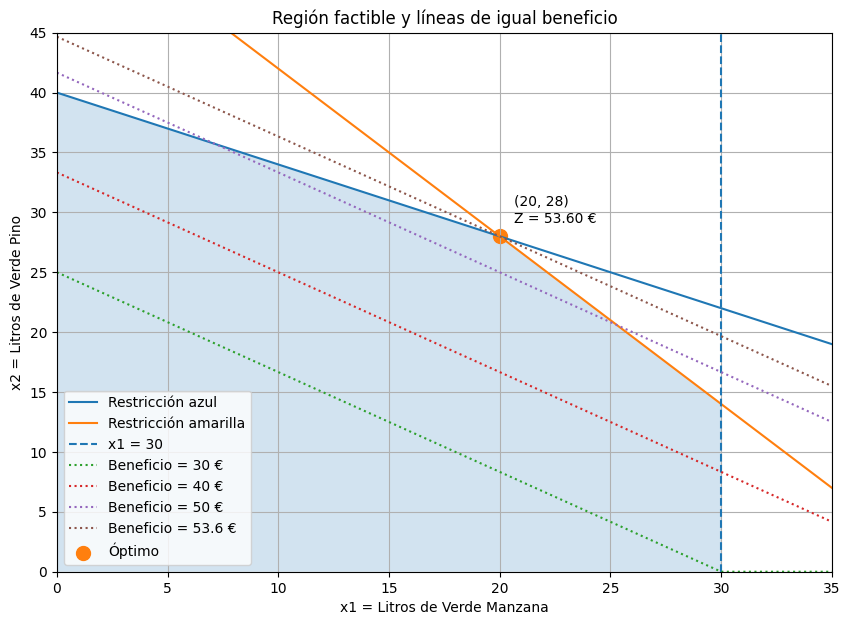

In [6]:
# Importar Pyomo
from pyomo.environ import *

# Importar librerías para la representación gráfica
import numpy as np
import matplotlib.pyplot as plt

# Crear el modelo
model = ConcreteModel()

# Definir las variables
# x1 = litros de Verde Manzana
# x2 = litros de Verde Pino
model.x1 = Var(within=NonNegativeReals)
model.x2 = Var(within=NonNegativeReals)

# Definir la función objetivo
# Beneficio de Verde Manzana = 1 €/litro
# Beneficio de Verde Pino = 1.20 €/litro
model.obj = Objective(
    expr=1 * model.x1 + 1.20 * model.x2,
    sense=maximize
)

# Restricción de pintura azul
# Hay disponibles 20 litros
model.constraint1 = Constraint(
    expr=0.3 * model.x1 + 0.5 * model.x2 <= 20
)

# Restricción de pintura amarilla
# Hay disponibles 28 litros
model.constraint2 = Constraint(
    expr=0.7 * model.x1 + 0.5 * model.x2 <= 28
)

# Restricción de producción de Verde Manzana
# No se pueden producir más de 30 litros
model.constraint3 = Constraint(
    expr=model.x1 <= 30
)

# Resolver el problema
solver = SolverFactory('glpk')
results = solver.solve(model)

# Mostrar el estado de la solución
print("Estado del solver:", results.solver.status)
print("Condición de terminación:", results.solver.termination_condition)

# Obtener los valores óptimos
x1_opt = value(model.x1)
x2_opt = value(model.x2)
beneficio_opt = value(model.obj)

# Mostrar los resultados
print()
print("RESULTADO ÓPTIMO")
print(f"Verde Manzana: {x1_opt:.2f} L")
print(f"Verde Pino: {x2_opt:.2f} L")
print(f"Beneficio máximo: {beneficio_opt:.2f} €")

# Calcular los recursos utilizados
azul_usado = 0.3 * x1_opt + 0.5 * x2_opt
amarillo_usado = 0.7 * x1_opt + 0.5 * x2_opt

print()
print("RECURSOS UTILIZADOS")
print(f"Pintura azul utilizada: {azul_usado:.2f} L de 20 L")
print(f"Pintura azul sobrante: {20 - azul_usado:.2f} L")
print(f"Pintura amarilla utilizada: {amarillo_usado:.2f} L de 28 L")
print(f"Pintura amarilla sobrante: {28 - amarillo_usado:.2f} L")

# Valores de x1 para representar las restricciones
x1 = np.linspace(0, 35, 400)

# Despejar x2 de la restricción de pintura azul
# 0.3x1 + 0.5x2 <= 20
# x2 <= 40 - 0.6x1
x2_azul = 40 - 0.6 * x1

# Despejar x2 de la restricción de pintura amarilla
# 0.7x1 + 0.5x2 <= 28
# x2 <= 56 - 1.4x1
x2_amarillo = 56 - 1.4 * x1

# Evitar valores negativos
x2_azul = np.maximum(x2_azul, 0)
x2_amarillo = np.maximum(x2_amarillo, 0)

# Crear la primera gráfica
plt.figure(figsize=(10, 7))

# Representar las restricciones
plt.plot(
    x1,
    x2_azul,
    label="Pintura azul"
)

plt.plot(
    x1,
    x2_amarillo,
    label="Pintura amarilla"
)

# Representar la restricción x1 <= 30
plt.axvline(
    30,
    linestyle="--",
    label="x1 = 30"
)

# Crear la región factible
x1_region = np.linspace(0, 30, 400)

limite_azul = 40 - 0.6 * x1_region
limite_amarillo = 56 - 1.4 * x1_region

limite = np.minimum(
    limite_azul,
    limite_amarillo
)

limite = np.maximum(limite, 0)

# Representar la región factible
plt.fill_between(
    x1_region,
    0,
    limite,
    alpha=0.25,
    label="Región factible"
)

# Marcar la solución óptima
plt.scatter(
    x1_opt,
    x2_opt,
    s=100,
    label="Solución óptima"
)

plt.annotate(
    f"Óptimo ({x1_opt:.0f}, {x2_opt:.0f})",
    (x1_opt, x2_opt),
    xytext=(10, 10),
    textcoords="offset points"
)

# Configurar la gráfica
plt.xlim(0, 35)
plt.ylim(0, 45)

plt.xlabel("x1 = Litros de Verde Manzana")
plt.ylabel("x2 = Litros de Verde Pino")

plt.title("Representación gráfica del problema")

plt.grid(True)
plt.legend()

plt.show()

# Representar las líneas de igual beneficio
# Z = x1 + 1.2x2
# x2 = (Z - x1) / 1.2

beneficios = [30, 40, 50, 53.6]

plt.figure(figsize=(10, 7))

# Representar las restricciones
plt.plot(
    x1,
    x2_azul,
    label="Restricción azul"
)

plt.plot(
    x1,
    x2_amarillo,
    label="Restricción amarilla"
)

plt.axvline(
    30,
    linestyle="--",
    label="x1 = 30"
)

# Representar la región factible
plt.fill_between(
    x1_region,
    0,
    limite,
    alpha=0.2
)

# Dibujar las líneas de igual beneficio
for z in beneficios:
    x2_obj = (z - x1) / 1.2
    x2_obj = np.maximum(x2_obj, 0)

    plt.plot(
        x1,
        x2_obj,
        linestyle=":",
        label=f"Beneficio = {z} €"
    )

# Marcar el punto óptimo
plt.scatter(
    x1_opt,
    x2_opt,
    s=100,
    label="Óptimo"
)

plt.annotate(
    f"({x1_opt:.0f}, {x2_opt:.0f})\nZ = {beneficio_opt:.2f} €",
    (x1_opt, x2_opt),
    xytext=(10, 10),
    textcoords="offset points"
)

# Configurar la gráfica
plt.xlim(0, 35)
plt.ylim(0, 45)

plt.xlabel("x1 = Litros de Verde Manzana")
plt.ylabel("x2 = Litros de Verde Pino")

plt.title("Región factible y líneas de igual beneficio")

plt.grid(True)
plt.legend()

plt.show()

## 8. Comparación e interpretación de los resultados

El modelo de programación lineal tiene como objetivo maximizar el beneficio obtenido por la producción de Verde Manzana y Verde Pino.

La función objetivo es:

$$
Z = x_1 + 1.2x_2
$$

donde:

- $x_1$ representa los litros de Verde Manzana.
- $x_2$ representa los litros de Verde Pino.

Después de resolver el modelo con Pyomo y GLPK, obtenemos:

| Concepto | Resultado |
|---|---:|
| Verde Manzana ($x_1$) | **20 L** |
| Verde Pino ($x_2$) | **28 L** |
| Beneficio máximo | **53,60 €** |
| Pintura azul utilizada | **20 L** |
| Pintura amarilla utilizada | **28 L** |
| Verde Manzana máximo permitido | 30 L |

### Comparación de diferentes planes

Podemos comparar la solución óptima con otras posibles combinaciones:

| Plan | Verde Manzana | Verde Pino | Beneficio |
|---|---:|---:|---:|
| Solo Verde Manzana | 30 L | 0 L | 30,00 € |
| Solo Verde Pino | 0 L | 40 L | 48,00 € |
| Plan 1 | 10 L | 28 L | 43,60 € |
| **Solución óptima** | **20 L** | **28 L** | **53,60 €** |
| Plan 3 | 25 L | 20 L | 49,00 € |

La solución obtenida por Pyomo es:

$$
(x_1,x_2)=(20,28)
$$

con un beneficio de:

$$
Z=1(20)+1.2(28)=53.60\,€
$$

### Interpretación de la gráfica

En la primera gráfica, la zona sombreada representa la **región factible**, es decir, todas las combinaciones de Verde Manzana y Verde Pino que cumplen las restricciones del problema.

El punto $(20,28)$ corresponde a la solución óptima encontrada por Pyomo.

Este punto se encuentra en la intersección de las restricciones de pintura azul y pintura amarilla:

$$
0.3(20)+0.5(28)=20
$$

y

$$
0.7(20)+0.5(28)=28
$$

Por tanto, se utilizan exactamente los recursos disponibles:

- 20 L de pintura azul.
- 28 L de pintura amarilla.

La restricción de producción de Verde Manzana no se alcanza:

$$
20 < 30
$$

por lo que todavía se podrían producir más litros de Verde Manzana desde el punto de vista de esta restricción, aunque no hay suficiente pintura azul y amarilla para aumentar la producción manteniendo todas las restricciones.

### Conclusión

La solución obtenida mediante Pyomo y la representación gráfica coinciden.

Por tanto, la combinación de producción obtenida es:

$$
\boxed{x_1=20\text{ L de Verde Manzana}}
$$

$$
\boxed{x_2=28\text{ L de Verde Pino}}
$$

y el beneficio máximo es:

$$
\boxed{53.60\,€}
$$

La representación gráfica permite comprobar visualmente que el punto $(20,28)$ pertenece a la región factible y corresponde al punto donde se alcanza el máximo beneficio.